In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pymatgen.io.vasp import Vasprun
from tqdm import tqdm

# ============================================================
# Base directory (50-atom systems)
# ============================================================
base_dir = "/home/jovyan/shared-scratch-kabdelma-pvc/kabdelma/computational-design-ductile-w-ta-nb-alloy/vasp_internal_elastic/sqs/elastic_50atoms"

# ============================================================
# Selected alloys ONLY
# ============================================================
folders = ["tanbw8", "ta3nbw6", "ta4nbw5", "ta7nbw2"]

# W percentage mapping
folder_to_w_percent = {
    "tanbw8": 80,   # W8TaNb
    "ta3nbw6": 60,  # W6Ta3Nb
    "ta4nbw5": 50,  # W5Ta4Nb
    "ta7nbw2": 20   # WTa8Nb
}

# Optional: nicer legend labels
folder_to_formula = {
    "tanbw8": r"W$_8$TaNb",
    "ta3nbw6": r"W$_6$Ta$_3$Nb",
    "ta4nbw5": r"W$_5$Ta$_4$Nb",
    "ta7nbw2": r"W$_2$Ta$_7$Nb"
}

# ============================================================
# Load DOS
# ============================================================
dos_data = {}

for folder in tqdm(folders):
    vr_path = os.path.join(base_dir, folder, "vasprun.xml")

    if not os.path.exists(vr_path):
        print(f"⚠️ Missing {vr_path} — skipping")
        continue

    vr = Vasprun(vr_path, parse_potcar_file=False)
    dos_data[folder] = vr.tdos

# ============================================================
# Sort by W content (for smooth colormap)
# ============================================================
sorted_folders = sorted(folders, key=lambda f: folder_to_w_percent[f])

100%|██████████| 4/4 [00:15<00:00,  3.80s/it]


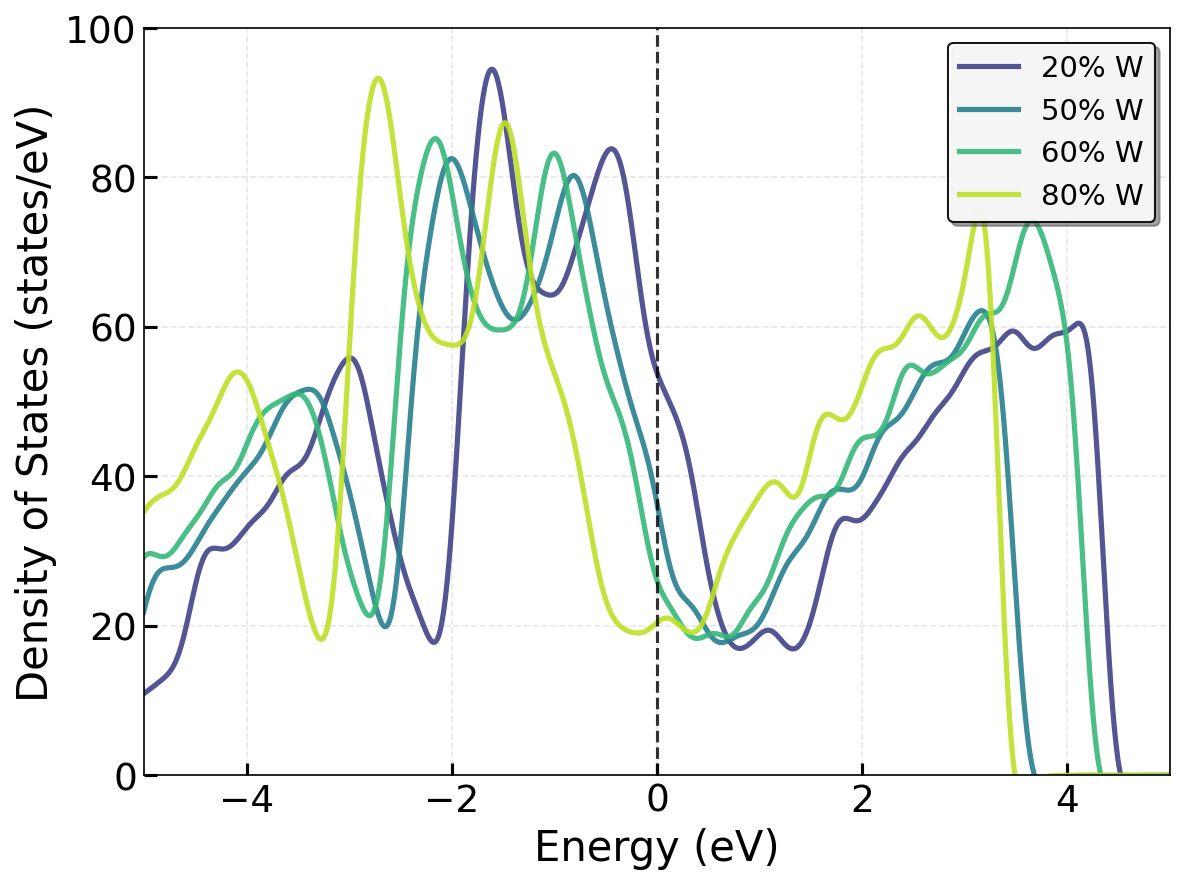

In [5]:
# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

colors = cm.viridis(np.linspace(0.2, 0.9, len(sorted_folders)))

for i, folder in enumerate(sorted_folders):
    if folder not in dos_data:
        continue

    tdos = dos_data[folder]

    energies = tdos.energies - tdos.efermi

    # Handle spin-polarized vs non-spin-polarized
    densities = tdos.densities
    if len(densities) == 1:
        total_dos = list(densities.values())[0]
    else:
        total_dos = sum(densities.values())

    # Label (choose one)
    label = f"{folder_to_w_percent[folder]}% W"
    # label = f"{folder_to_formula[folder]} ({folder_to_w_percent[folder]}%)"

    ax.plot(
        energies,
        total_dos,
        color=colors[i],
        linewidth=2.5,
        alpha=0.9,
        label=label
    )

# ============================================================
# Styling
# ============================================================
ax.set_xlabel("Energy (eV)", fontsize=20)
ax.set_ylabel("Density of States (states/eV)", fontsize=20)

ax.set_xlim(-5, 5)
ax.set_ylim(0, 100)

# Fermi level
ax.axvline(0, color="black", linestyle="--", linewidth=1.5, alpha=0.8)

# Ticks
ax.tick_params(axis="both",
               which="major",
               labelsize=18,
               direction="in",
               width=1.5,
               length=6)

# Grid
ax.grid(True, linestyle="--", alpha=0.3)

# Legend
ax.legend(fontsize=14,
          loc="upper right",
          frameon=True,
          fancybox=True,
          shadow=True,
          framealpha=0.9,
          edgecolor='black')

plt.tight_layout()
plt.show()

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pymatgen.io.vasp import Vasprun
from tqdm import tqdm

# ============================================================
# Base directories
# ============================================================
base_dir_10 = "../vasp_internal_elastic/sqs/elastic"
base_dir_50 = "/home/jovyan/shared-scratch-kabdelma-pvc/kabdelma/computational-design-ductile-w-ta-nb-alloy/vasp_internal_elastic/sqs/elastic_50atoms"

# ============================================================
# Selected alloys
# ============================================================
folders = ["ta2nbw7", "ta3nbw6"]

# Mapping for W percentage (used for sorting/colors)
folder_to_w_percent = {
    "ta2nbw7": 70,
    "ta3nbw6": 60,
}

# Mapping for the Legend Formulas (using LaTeX formatting)
folder_to_formula = {
    "ta2nbw7": r"W$_7$Ta$_2$Nb",
    "ta3nbw6": r"W$_6$Ta$_3$Nb",
}

# ============================================================
# Helper function to load DOS
# ============================================================
def load_dos(base_dir, folders):
    dos_dict = {}
    natoms_dict = {}

    for folder in tqdm(folders, desc=f"Loading {os.path.basename(base_dir)}"):
        vr_path = os.path.join(base_dir, folder, "vasprun.xml")

        if not os.path.exists(vr_path):
            print(f"⚠️ Missing {vr_path}")
            continue

        # Added optimization to keep it fast
        vr = Vasprun(vr_path, parse_potcar_file=False, parse_eigen=False, parse_projected_eigen=False)

        dos_dict[folder] = vr.tdos
        natoms_dict[folder] = len(vr.final_structure) 

    return dos_dict, natoms_dict

# ============================================================
# Load both datasets
# ============================================================
dos_10, natoms_10 = load_dos(base_dir_10, folders)
dos_50, natoms_50 = load_dos(base_dir_50, folders)


Loading elastic_50atoms: 100%|██████████| 2/2 [00:08<00:00,  4.23s/it]


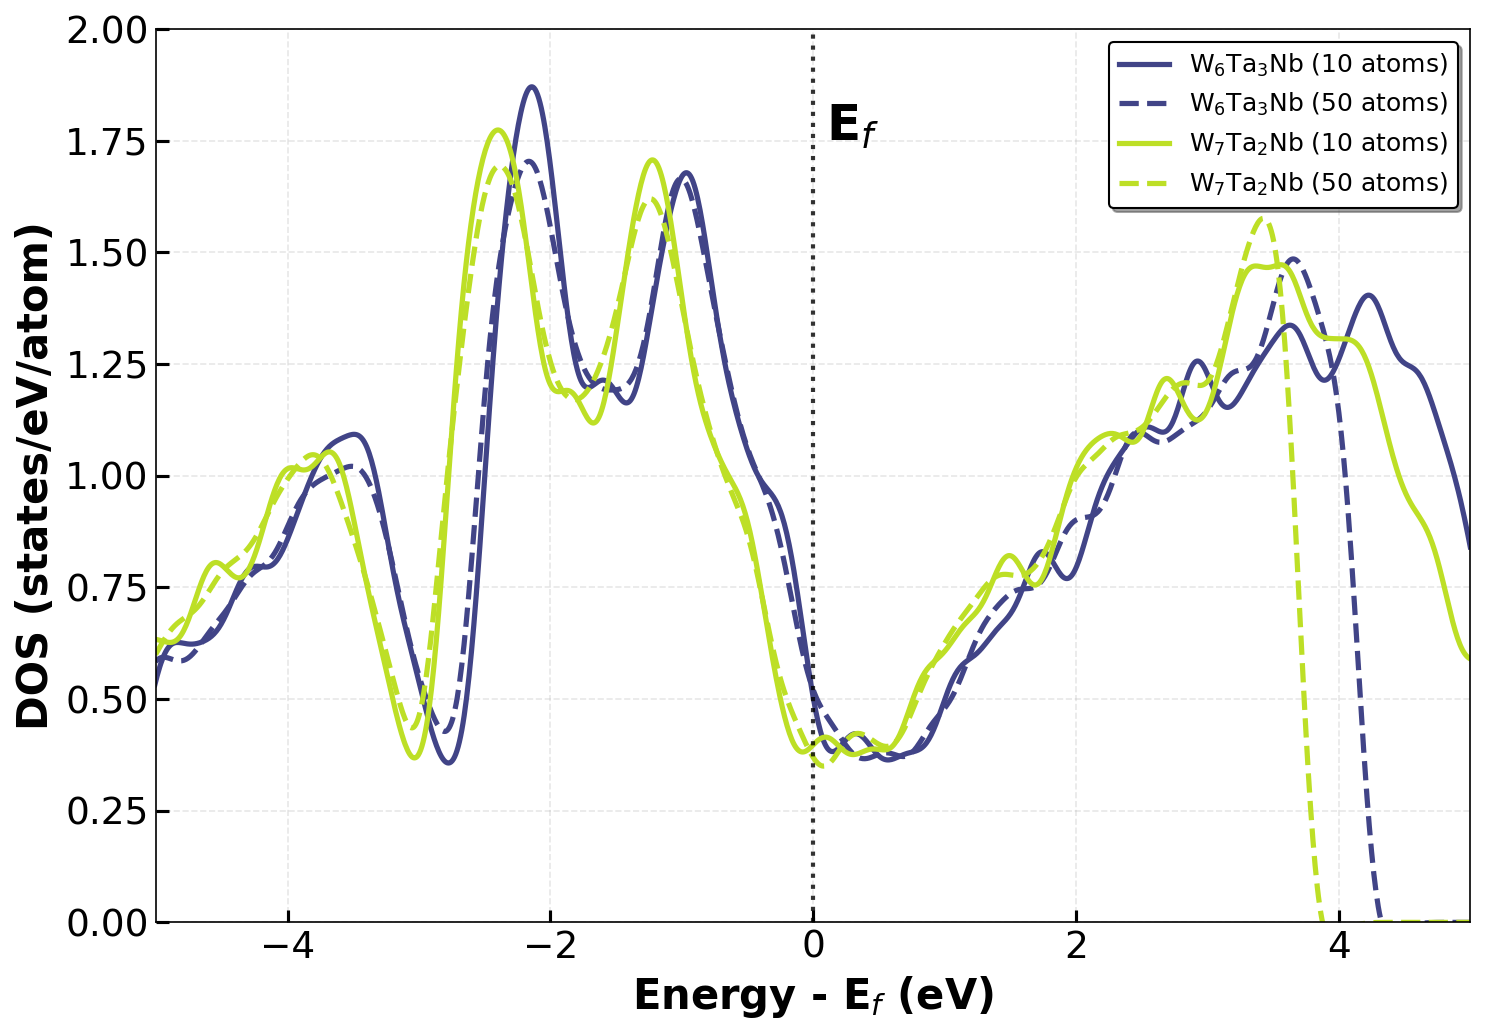

In [36]:

# ============================================================
# Sort folders by composition (ensures consistent colors)
# ============================================================
sorted_folders = sorted(folders, key=lambda f: folder_to_w_percent[f])
colors = cm.viridis(np.linspace(0.2, 0.9, len(sorted_folders)))

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(figsize=(10, 7), dpi=150)

for i, folder in enumerate(sorted_folders):
    color = colors[i]
    # Get the clean formula name for the legend
    formula = folder_to_formula.get(folder, folder)

    # -------------------------
    # 10-atom (SOLID)
    # -------------------------
    if folder in dos_10:
        tdos = dos_10[folder]
        n_atoms = natoms_10[folder]
        energies = tdos.energies - tdos.efermi
        densities = tdos.densities
        total_dos = sum(densities.values()) if len(densities) > 1 else list(densities.values())[0]
        
        ax.plot(
            energies,
            total_dos / n_atoms,
            color=color,
            linewidth=2.5,
            linestyle='-',
            label=f"{formula} (10 atoms)"
        )

    # -------------------------
    # 50-atom (DASHED)
    # -------------------------
    if folder in dos_50:
        tdos = dos_50[folder]
        n_atoms = natoms_50[folder]
        energies = tdos.energies - tdos.efermi
        densities = tdos.densities
        total_dos = sum(densities.values()) if len(densities) > 1 else list(densities.values())[0]

        ax.plot(
            energies,
            total_dos / n_atoms,
            color=color,
            linewidth=2.5,
            linestyle='--',
            label=f"{formula} (50 atoms)"
        )

# ============================================================
# Styling
# ============================================================
ax.set_xlabel("Energy - E$_f$ (eV)", fontsize=20, fontweight='bold')
ax.set_ylabel("DOS (states/eV/atom)", fontsize=20, fontweight='bold')

ax.set_xlim(-5, 5)
ax.set_ylim(0, 2) 

# Fermi level line
ax.axvline(0, color="black", linestyle=":", linewidth=2, alpha=0.8)
ax.text(0.1, 1.75, 'E$_f$', fontsize=24, fontweight='bold')

# Ticks and Grid
ax.tick_params(axis="both", which="major", labelsize=18, direction="in", width=1.5, length=6)
ax.grid(True, linestyle="--", alpha=0.3)

# Legend
ax.legend(fontsize=12, loc="upper right", frameon=True, shadow=True, framealpha=1, edgecolor='black')

plt.tight_layout()
plt.show()

100%|██████████| 4/4 [00:18<00:00,  4.69s/it]


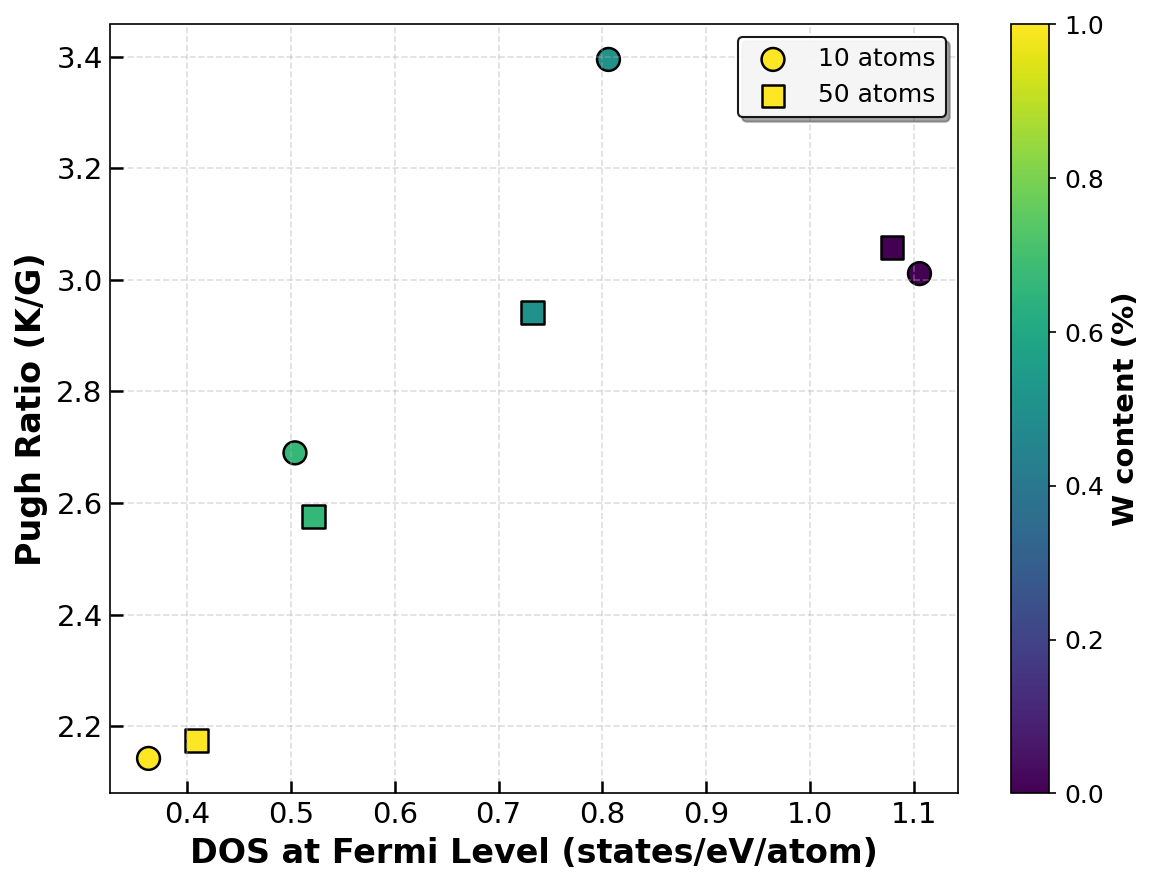

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.io.vasp import Vasprun, Outcar
from pymatgen.analysis.elasticity import ElasticTensor
from tqdm import tqdm

# -----------------------
# Directories
# -----------------------
base_dir_10 = "../vasp_internal_elastic/sqs/elastic"
base_dir_50 = "/home/jovyan/shared-scratch-kabdelma-pvc/kabdelma/computational-design-ductile-w-ta-nb-alloy/vasp_internal_elastic/sqs/elastic_50atoms"

# Selected alloys
folders = ["tanbw8", "ta3nbw6", "ta4nbw5", "ta7nbw2"]

# W fractions (%)
folder_to_w_percent = {
    "tanbw8": 80,
    "ta3nbw6": 60,
    "ta4nbw5": 50,
    "ta7nbw2": 20
}

# -----------------------
# Function: DOS at Ef per atom
# -----------------------
def dos_at_ef_per_atom(base_dir, folders):
    dos_vals = []
    w_perc = []

    for folder in tqdm(folders):
        vr_path = os.path.join(base_dir, folder, "vasprun.xml")
        if not os.path.exists(vr_path):
            print(f"⚠️ Missing {vr_path}")
            continue

        vr = Vasprun(vr_path, parse_potcar_file=False)
        n_atoms = len(vr.final_structure)
        tdos = vr.tdos

        # Total DOS
        densities = tdos.densities
        if len(densities) == 1:
            total_dos = list(densities.values())[0]
        else:
            total_dos = sum(densities.values())

        # Find index closest to Fermi energy
        energies = np.array(tdos.energies)
        idx = np.argmin(np.abs(energies - tdos.efermi))

        # DOS at Ef per atom
        dos_ef = total_dos[idx] / n_atoms

        dos_vals.append(dos_ef)
        w_perc.append(folder_to_w_percent[folder])

    return np.array(w_perc), np.array(dos_vals)

# -----------------------
# Function: Compute Pugh ratio (K/G)
# -----------------------
def compute_pugh(base_dir, folders):
    rows = []
    for folder in folders:
        outcar_path = os.path.join(base_dir, folder, "OUTCAR")
        if not os.path.exists(outcar_path):
            print(f"⚠️ Missing {outcar_path}")
            continue

        out = Outcar(outcar_path)
        out.read_elastic_tensor()
        C_gpa = np.array(out.data["elastic_tensor"]) / 10.0  # kBar → GPa
        tensor = ElasticTensor.from_voigt(C_gpa)
        k_vrh = tensor.k_vrh
        g_vrh = tensor.g_vrh
        pugh = k_vrh / g_vrh
        rows.append({"folder": folder, "pugh": pugh})
    df = pd.DataFrame(rows)
    return df

# -----------------------
# Load data
# -----------------------
w_10, dos_10 = dos_at_ef_per_atom(base_dir_10, folders)
w_50, dos_50 = dos_at_ef_per_atom(base_dir_50, folders)

df_pugh_10 = compute_pugh(base_dir_10, folders)
df_pugh_50 = compute_pugh(base_dir_50, folders)

# Align DOS and Pugh by folder
pugh_10 = np.array([df_pugh_10.loc[df_pugh_10.folder==f, "pugh"].values[0] for f in folders])
pugh_50 = np.array([df_pugh_50.loc[df_pugh_50.folder==f, "pugh"].values[0] for f in folders])

# -----------------------
# Plot
# -----------------------
plt.figure(figsize=(8,6), dpi=150)

# 10-atom scatter (circle)
plt.scatter(dos_10, pugh_10, c=w_10, cmap='viridis', s=120,
            edgecolor='black', linewidth=1.2, marker='o', label='10 atoms')

# 50-atom scatter (square)
plt.scatter(dos_50, pugh_50, c=w_50, cmap='viridis', s=120,
            edgecolor='black', linewidth=1.2, marker='s', label='50 atoms')

# Colorbar for W content
sc = plt.scatter([], [], c=[], cmap='viridis')  # dummy for colorbar
cbar = plt.colorbar(sc)
cbar.set_label("W content (%)", fontsize=14, fontweight='bold')
cbar.ax.tick_params(labelsize=12)

# Labels and styling
plt.xlabel("DOS at Fermi Level (states/eV/atom)", fontsize=16, fontweight='bold')
plt.ylabel("Pugh Ratio (K/G)", fontsize=16, fontweight='bold')
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tick_params(direction='in', length=6, width=1.2)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(fontsize=12, frameon=True, fancybox=True, shadow=True, framealpha=0.9, edgecolor='black')
plt.tight_layout()
plt.show()

Reading elastic_50atoms: 100%|██████████| 8/8 [05:29<00:00, 41.21s/it]


ValueError: Unable to determine Axes to steal space for Colorbar. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.

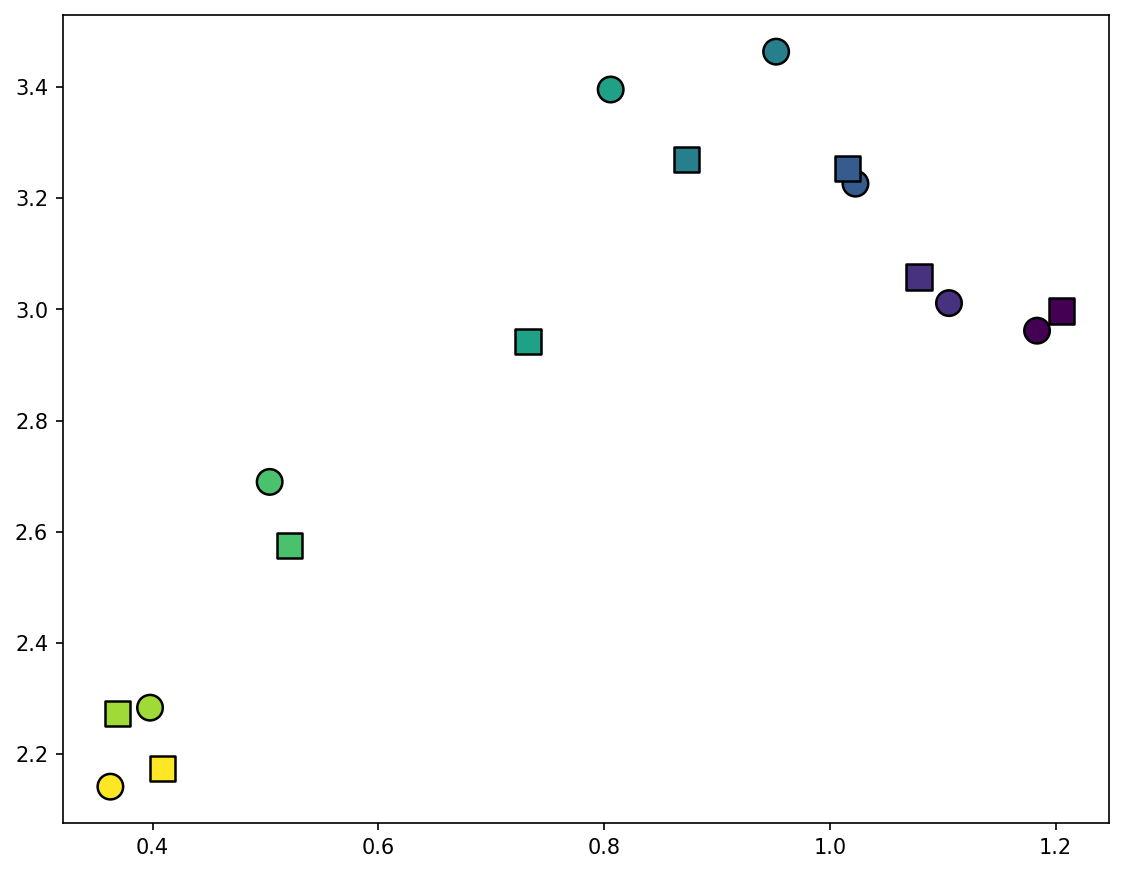

In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.io.vasp import Vasprun, Outcar
from pymatgen.analysis.elasticity import ElasticTensor
from tqdm import tqdm

# -----------------------
# Configuration & Alloy Mapping
# -----------------------
base_dir_10 = "../vasp_internal_elastic/sqs/elastic"
base_dir_50 = "/home/jovyan/shared-scratch-kabdelma-pvc/kabdelma/computational-design-ductile-w-ta-nb-alloy/vasp_internal_elastic/sqs/elastic_50atoms"

# Updated list of all alloys
folders = [
    "tanbw8", "ta2nbw7", "ta3nbw6", "ta4nbw5", 
    "ta5nbw4", "ta6nbw3", "ta7nbw2", "ta8nbw"
]

# W fractions (%) based on your naming convention
folder_to_w_percent = {
    "tanbw8": 80, "ta2nbw7": 70, "ta3nbw6": 60, "ta4nbw5": 50,
    "ta5nbw4": 40, "ta6nbw3": 30, "ta7nbw2": 20, "ta8nbw": 10
}

# -----------------------
# Optimized Data Extraction Function
# -----------------------
def get_alloy_data(base_dir, folders_list):
    data = []
    for folder in tqdm(folders_list, desc=f"Reading {os.path.basename(base_dir)}"):
        path = os.path.join(base_dir, folder)
        vr_path = os.path.join(path, "vasprun.xml")
        out_path = os.path.join(path, "OUTCAR")

        if not (os.path.exists(vr_path) and os.path.exists(out_path)):
            # Silently skip missing folders to keep the log clean, or print if debugging
            continue

        try:
            # OPTIMIZATION: skip eigenvalues to save massive amounts of time/RAM
            vr = Vasprun(vr_path, parse_potcar_file=False, parse_eigen=False, parse_projected_eigen=False)
            n_atoms = len(vr.final_structure)
            tdos = vr.tdos
            
            # Get DOS at Fermi level
            energies = np.array(tdos.energies)
            idx = np.argmin(np.abs(energies - tdos.efermi))
            total_densities = sum(tdos.densities.values()) if len(tdos.densities) > 1 else list(tdos.densities.values())[0]
            dos_ef = total_densities[idx] / n_atoms

            # Get Elastic Pugh Ratio
            out = Outcar(out_path)
            out.read_elastic_tensor()
            C_gpa = np.array(out.data["elastic_tensor"]) / 10.0
            tensor = ElasticTensor.from_voigt(C_gpa)
            
            data.append({
                "folder": folder,
                "w_perc": folder_to_w_percent[folder],
                "dos_ef": dos_ef,
                
                "pugh": tensor.k_vrh / tensor.g_vrh
            })
        except Exception as e:
            print(f"Error processing {folder}: {e}")
            
    return pd.DataFrame(data)

# -----------------------
# Load Data
# -----------------------
df_10 = get_alloy_data(base_dir_10, folders)
df_50 = get_alloy_data(base_dir_50, folders)

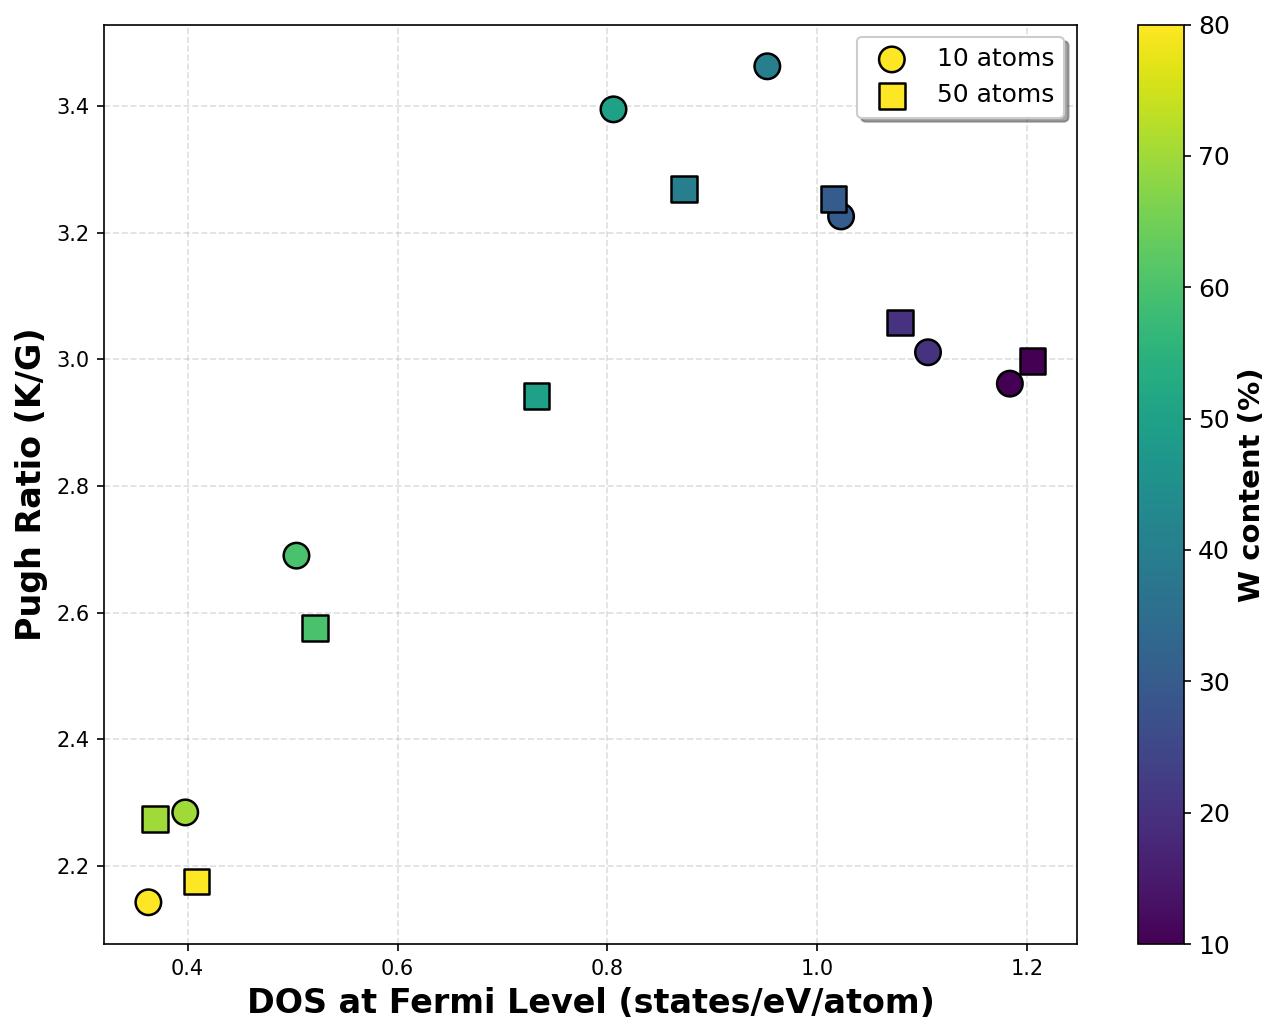

In [22]:
# -----------------------
# Plotting
# -----------------------
plt.figure(figsize=(9, 7), dpi=150)

# Plot 10-atom data
if not df_10.empty:
    plt.scatter(df_10['dos_ef'], df_10['pugh'], c=df_10['w_perc'], 
                cmap='viridis', s=150, vmin=10, vmax=80,
                edgecolor='black', linewidth=1.2, marker='o', label='10 atoms', zorder=3)

# Plot 50-atom data
if not df_50.empty:
    plt.scatter(df_50['dos_ef'], df_50['pugh'], c=df_50['w_perc'], 
                cmap='viridis', s=150, vmin=10, vmax=80,
                edgecolor='black', linewidth=1.2, marker='s', label='50 atoms', zorder=3)

# -----------------------
# Colorbar setup
# -----------------------
# Use the ScalarMappable but explicitly tell it which Axes to use
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=10, vmax=80))
sm.set_array([])

# Add 'ax=plt.gca()' to tell matplotlib to steal space from the current plot
cbar = plt.colorbar(sm, ax=plt.gca()) 
cbar.set_label("W content (%)", fontsize=14, fontweight='bold')
cbar.ax.tick_params(labelsize=12)

# Styling
plt.xlabel("DOS at Fermi Level (states/eV/atom)", fontsize=16, fontweight='bold')
plt.ylabel("Pugh Ratio (K/G)", fontsize=16, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.4, zorder=0)
plt.legend(fontsize=12, frameon=True, shadow=True)
plt.tight_layout()

plt.show()

In [23]:
df_10

,folder,w_perc,dos_ef,pugh
0,tanbw8,80,0.36256,2.141900
1,ta2nbw7,70,0.39769,2.283924
2,ta3nbw6,60,0.50368,2.689889
3,ta4nbw5,50,0.80584,3.395395
4,ta5nbw4,40,0.95243,3.463458
5,ta6nbw3,30,1.02272,3.226145
6,ta7nbw2,20,1.10558,3.011365
7,ta8nbw,10,1.18360,2.961799


In [24]:
df_50

,folder,w_perc,dos_ef,pugh
0,tanbw8,80,0.408562,2.174723
1,ta2nbw7,70,0.368816,2.273583
2,ta3nbw6,60,0.521200,2.575462
3,ta4nbw5,50,0.732382,2.942141
4,ta5nbw4,40,0.873110,3.269478
5,ta6nbw3,30,1.015732,3.253450
6,ta7nbw2,20,1.079108,3.058437
7,ta8nbw,10,1.205290,2.997179
